# Main analysis

add explanation later

## Calibration charts

A market is calibrated if things priced at 70% happen about 70% of the time.

For each time point (7, 3 and 1 day before the deadline):
1. Put every market into a price band (0–20%, 20–40%, 40–60%, 60–80%, 80–100%) using its price at that time point
2. For each band, work out the **average price** (what the market said) and the **share that resolved Yes** (what happened)
3. Plot one dot per band: average price across, share that resolved Yes up, plus the 45 degree line where the two are equal

Dots below the line were overpriced (happened less often than the price said), dots above it were underpriced.

In [72]:
import pandas as pd
from matplotlib import pyplot as plt
from statsmodels.stats.proportion import proportion_confint

Settings: the band edges and their labels, and which column holds the price at each time point

The last edge is slightly above 1 so that a price of exactly 1 still falls into the 80–100% band

In [73]:
BAND_EDGES = [0, 0.2, 0.4, 0.6, 0.8, 1.000001]
BAND_LABELS = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]
TIME_POINTS = {"7 days before": "price_7d",
               "3 days before": "price_3d",
               "1 day before": "price_1d"}

`calibration_table` puts the markets into price bands using `price_column`, and returns one row per band with the number of markets, the number that resolved Yes, the average price and the share that resolved Yes

It also adds the 95% exact (Clopper–Pearson) range for the share that resolved Yes: `lower` and `upper`. These are the error bars on the charts. Empty bands get no range

In [74]:
def calibration_table(markets, price_column):
    band = pd.cut(markets[price_column], bins=BAND_EDGES, labels=BAND_LABELS, right=False)
    table = markets.groupby(band, observed=False).agg(
        markets=("outcome", "size"),
        yes_count=("outcome", "sum"),
        average_price=(price_column, "mean"),
        share_yes=("outcome", "mean"),
    )

    has_markets = table["markets"] > 0
    lower, upper = proportion_confint(table.loc[has_markets, "yes_count"],
                                      table.loc[has_markets, "markets"],
                                      alpha=0.05, method="beta")
    table.loc[has_markets, "lower"] = lower
    table.loc[has_markets, "upper"] = upper
    return table

`plot_calibration_chart` draws one chart for one time point: a dot per price band, its 95% exact error bar and the 45° line

A band only counts as mispriced if its error bar misses the 45° line

Every chart uses the same axes (−5% to 105% on both), so the three time points can be compared directly

The small number next to each dot is how many markets are in that band: fewer markets means a longer error bar

In [75]:
def plot_calibration_chart(markets, category_name, time_point, price_column):
    table = calibration_table(markets, price_column)
    table = table[table["markets"] > 0]
    figure, chart = plt.subplots(figsize=(6, 6))

    chart.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")

    distance_down = table["share_yes"] - table["lower"]
    distance_up = table["upper"] - table["share_yes"]
    chart.errorbar(table["average_price"], table["share_yes"],
                   yerr=[distance_down, distance_up],
                   fmt="o", markersize=8, capsize=4,
                   label="price band, 95% exact range")

    for band_label, row in table.iterrows():
        chart.annotate(f"n={int(row['markets'])}", (row["average_price"], row["share_yes"]),
                       textcoords="offset points", xytext=(7, 4), fontsize=8)

    chart.set_title(f"{category_name}: {time_point} the deadline")
    chart.set_xlim(-0.05, 1.05)
    chart.set_ylim(-0.05, 1.05)
    chart.set_aspect("equal")
    chart.set_xlabel("Average price in band")
    chart.set_ylabel("Share that resolved Yes")
    chart.grid(alpha=0.3)
    chart.legend(loc="upper left")
    figure.tight_layout()
    plt.show()

# Politics

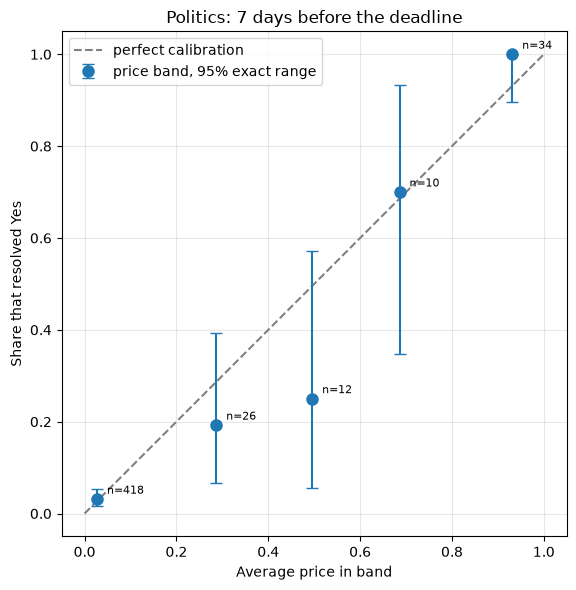

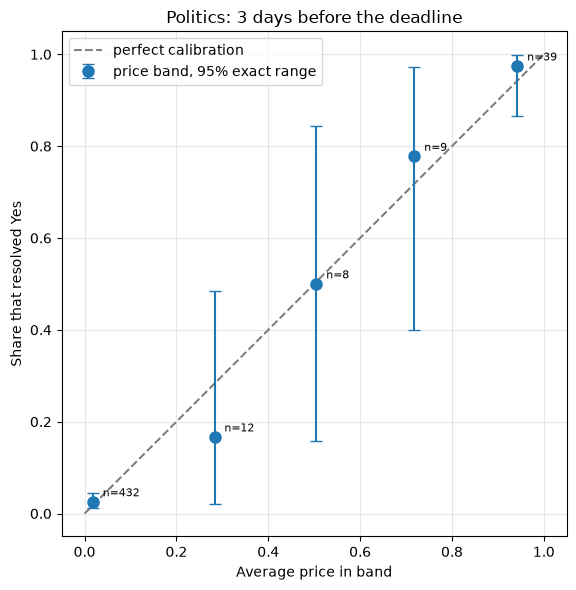

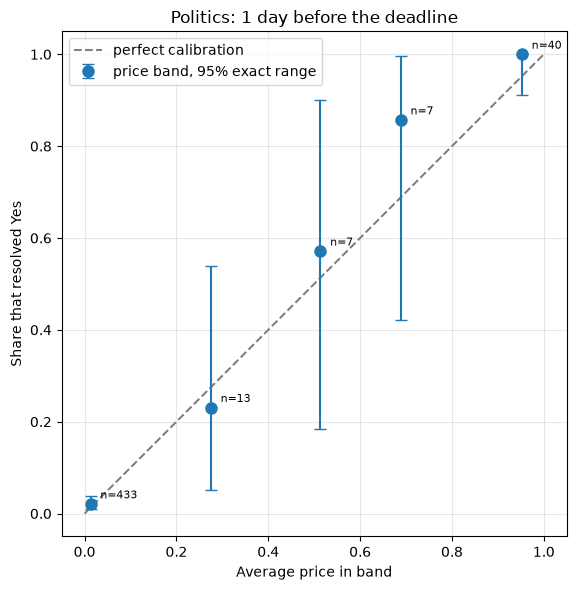

In [76]:
politics = pd.read_csv("politics/politics.csv")

for time_point, price_column in TIME_POINTS.items():
    plot_calibration_chart(politics, "Politics", time_point, price_column)

# Sports

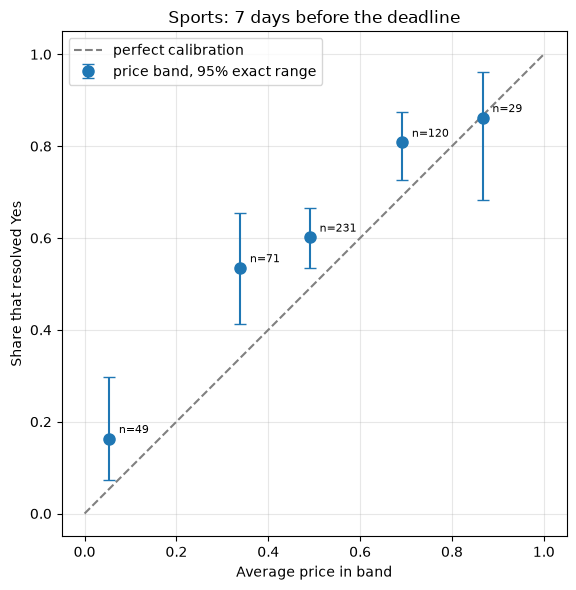

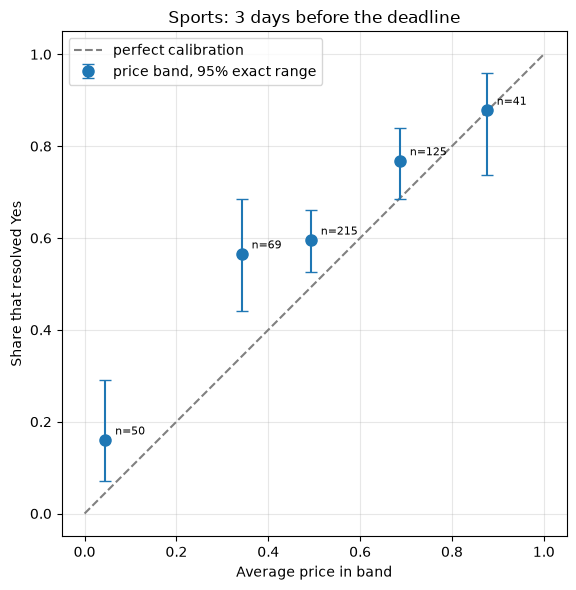

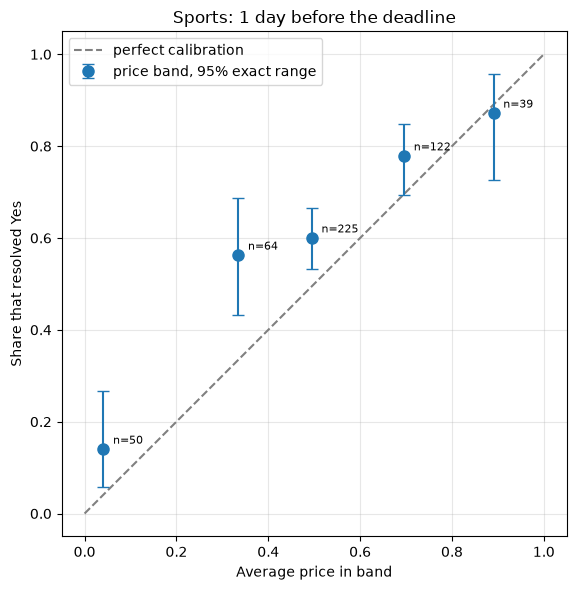

In [77]:
sports = pd.read_csv("sports/sports.csv")

for time_point, price_column in TIME_POINTS.items():
    plot_calibration_chart(sports, "Sports", time_point, price_column)

# Tech

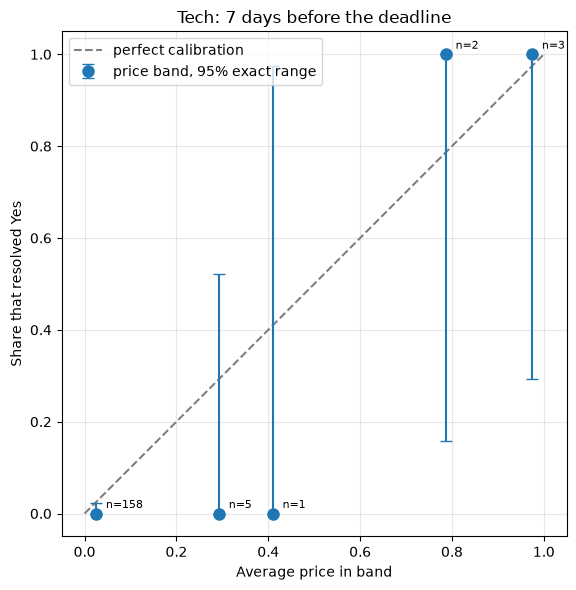

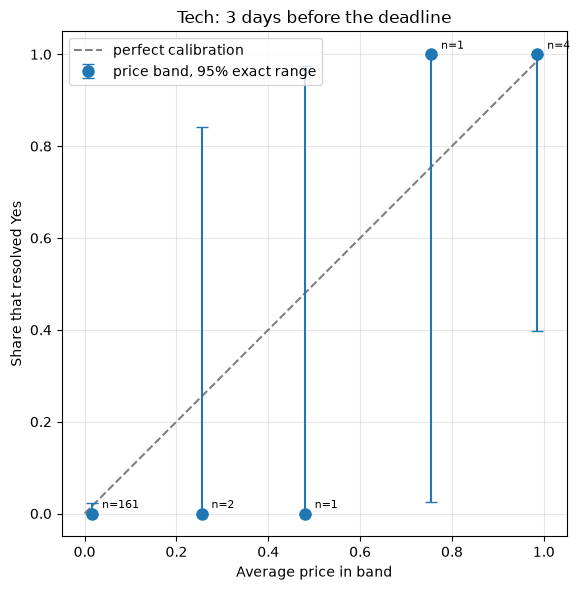

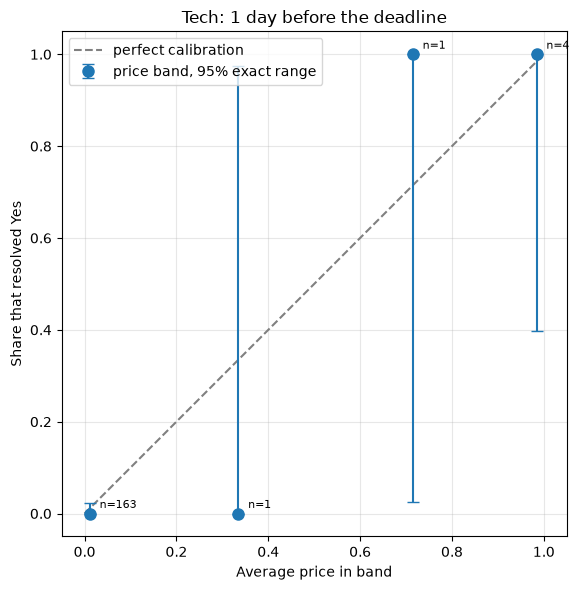

In [78]:
tech = pd.read_csv("tech/tech.csv")

for time_point, price_column in TIME_POINTS.items():
    plot_calibration_chart(tech, "Tech", time_point, price_column)

# Crypto

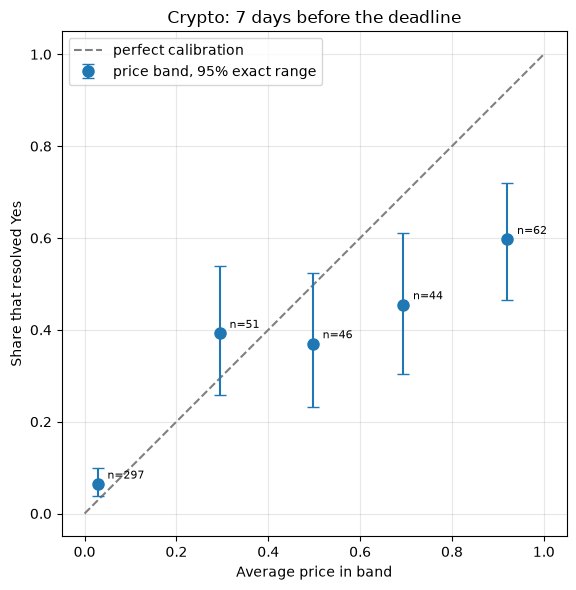

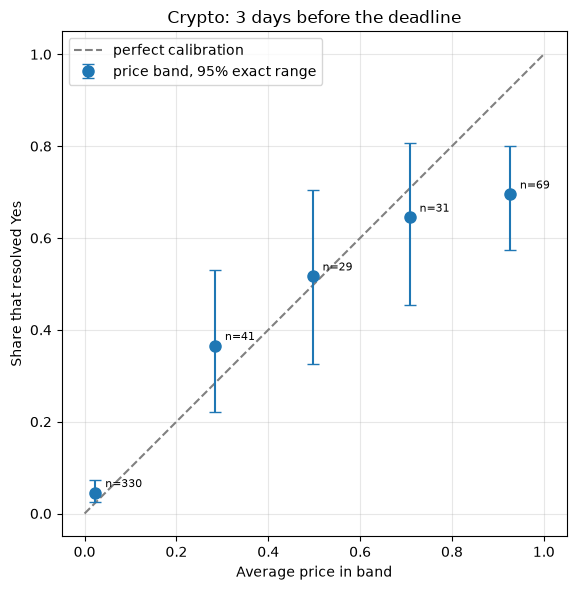

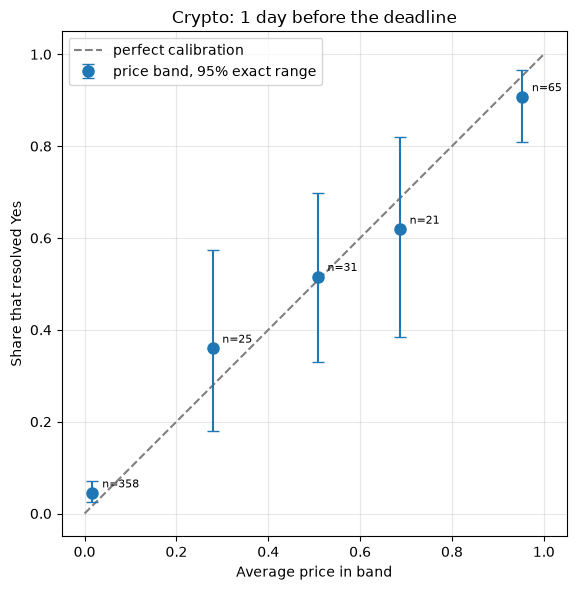

In [79]:
crypto = pd.read_csv("crypto/crypto.csv")

for time_point, price_column in TIME_POINTS.items():
    plot_calibration_chart(crypto, "Crypto", time_point, price_column)

# Main table

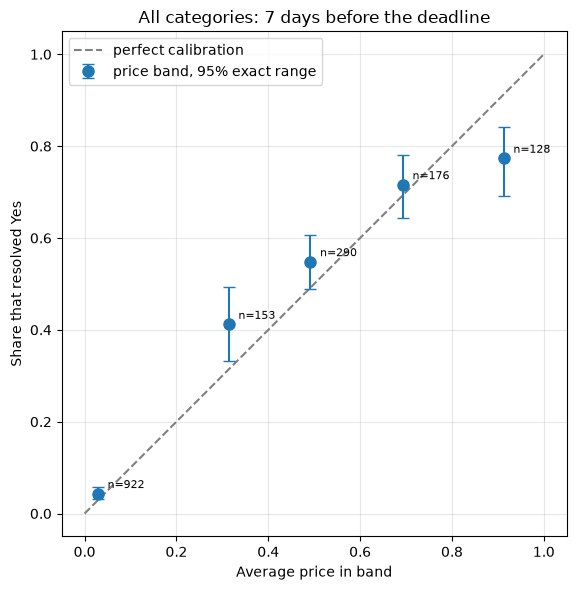

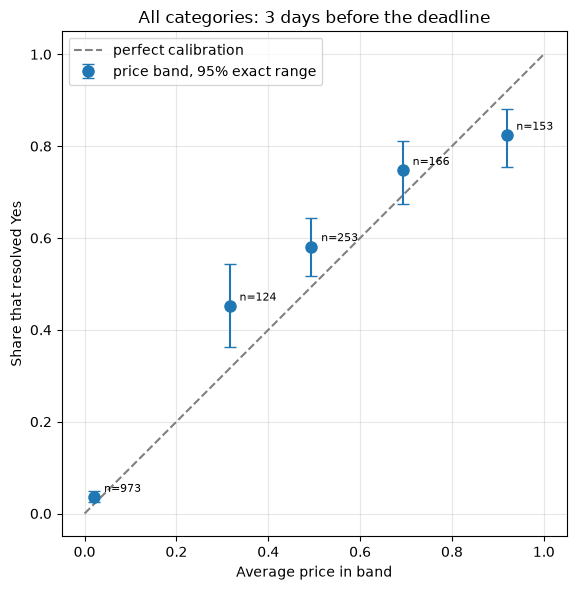

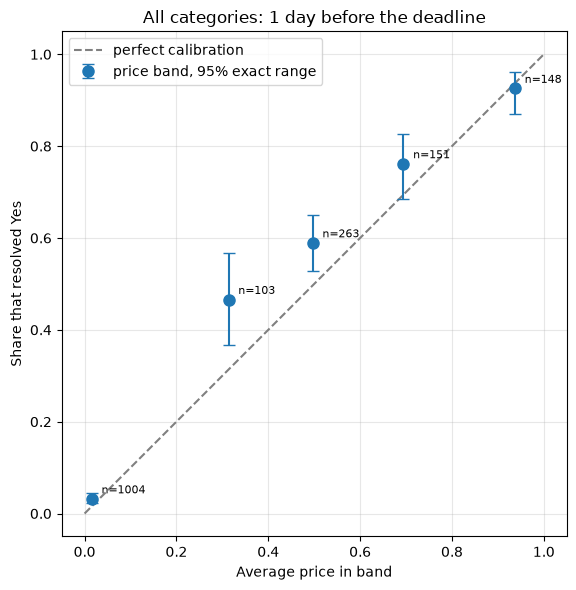

In [80]:
main_table = pd.concat([politics, sports, crypto, tech], ignore_index=True)

for time_point, price_column in TIME_POINTS.items():
    plot_calibration_chart(main_table, "All categories", time_point, price_column)